<a href="https://colab.research.google.com/github/PavloIeremeiew/BD_FIT_1-7m/blob/main/BD_Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [21]:
import pyspark
from pyspark.sql import SparkSession
import re
import random
import matplotlib.pyplot as plt
from google.colab import files
import os

In [2]:
# Ініціалізація Spark середовища
spark = SparkSession.builder.appName("Lab2_Variant2").master("local[*]").getOrCreate()
sc = spark.sparkContext

In [3]:
# 1. Створення RDD (список слів із дублікатами, > 100 слів)
base_words = ["apple", "banana", "berry", "cherry", "blueberry", "bluebErry","apricot", "blackberry", "melon", "bread"]
words_data = base_words * 15 # створення масиву з 135 слів
rdd_words = sc.parallelize(words_data)
print(words_data)

['apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry', 'blueberry', 'bluebErry', 'apricot', 'blackberry', 'melon', 'bread', 'apple', 'banana', 'berry', 'cherry'

In [4]:
# 2. Трансформації над RDD
# Перетворення на великі літери
rdd_upper = rdd_words.map(lambda word: word.upper())
# Фільтрація: лише слова, що починаються на "B"
rdd_b_words = rdd_upper.filter(lambda word: word.startswith("B"))
# Видалення дублікатів
rdd_distinct = rdd_b_words.distinct()

print("Унікальні слова на 'B':", rdd_distinct.collect())

Унікальні слова на 'B': ['BERRY', 'BREAD', 'BANANA', 'BLUEBERRY', 'BLACKBERRY']


In [5]:
# 3. Робота з числовими даними
# RDD з 100 випадкових чисел від 1 до 50
numbers_data = [random.randint(1, 50) for _ in range(100)]
rdd_nums = sc.parallelize(numbers_data)

# Піднесення до квадрату
rdd_squared = rdd_nums.map(lambda x: x ** 2)
# Відбір парних чисел
rdd_even = rdd_squared.filter(lambda x: x % 2 == 0)
# Підрахунок парних чисел (Дія)
even_count = rdd_even.count()
print("Кількість парних квадратів чисел:", even_count)

Кількість парних квадратів чисел: 47


In [6]:
# 4. Агрегація даних
# Сума всіх елементів (оригінальний масив)
total_sum = rdd_nums.reduce(lambda a, b: a + b)
print("Сума всіх елементів:", total_sum)

# Добуток всіх елементів (беремо перші 10 чисел, щоб уникнути переповнення)
rdd_small_nums = sc.parallelize(numbers_data[:10])
total_product = rdd_small_nums.reduce(lambda a, b: a * b)
print("Добуток перших 10 елементів:", total_product)

Сума всіх елементів: 2417
Добуток перших 10 елементів: 1411198588800


In [7]:
# 5. Кешування
rdd_nums.cache()
# Демонстрація використання кешу (дії виконуються швидше при повторному виклику)
print("Кількість елементів (виклик 1):", rdd_nums.count())
print("Кількість елементів (виклик 2):", rdd_nums.count())

Кількість елементів (виклик 1): 100
Кількість елементів (виклик 2): 100


In [9]:
#ЧАСТИНА 2.  (Аналіз журналів сервера)
# Генерація 100+ записів лог-файлу для прикладу
log_statuses = ["200", "404", "500", "403"]
log_ips = ["192.168.1.10", "10.0.0.5", "127.0.0.1", "172.16.0.2"]
logs_data = []
for i in range(120):
    ip = random.choice(log_ips)
    status = random.choice(log_statuses)
    # Формат логу: IP - - [Дата] "Запит" Статус Розмір
    log_line = f'{ip} - - [10/Oct/2023:13:55:36] "GET /index.html HTTP/1.1" {status} 2326'
    logs_data.append(log_line)

In [10]:
rdd_logs = sc.parallelize(logs_data)

# Фільтрація: успішні запити (статус 200)
# Логіка: розбиваємо рядок по пробілах і беремо передостанній елемент (статус)
rdd_successful = rdd_logs.filter(lambda line: line.split()[-2] == "200")
print(f"Кількість успішних запитів (200): {rdd_successful.count()}")

Кількість успішних запитів (200): 20


In [11]:
# Обчислення кількості запитів за IP-адресою (map + reduceByKey)
rdd_ip_requests = (rdd_logs
                   .map(lambda line: (line.split()[0], 1))
                   .reduceByKey(lambda a, b: a + b))

print("Топ запитів за IP-адресами:")
for ip, count in rdd_ip_requests.take(10):
    print(f"IP: {ip} -> {count} запитів")

Топ запитів за IP-адресами:
IP: 127.0.0.1 -> 41 запитів
IP: 172.16.0.2 -> 34 запитів
IP: 10.0.0.5 -> 20 запитів
IP: 192.168.1.10 -> 25 запитів


In [12]:
# Групування запитів за статусами (groupBy)
rdd_status_group = rdd_logs.groupBy(lambda line: line.split()[-2])
# Перетворюємо згруповані об'єкти на підрахунок кількості
status_counts = rdd_status_group.map(lambda x: (x[0], len(list(x[1]))))

print("Кількість запитів за статусами:")
for status, count in status_counts.take(10):
    print(f"Статус {status}: {count} запитів")

Кількість запитів за статусами:
Статус 403: 30 запитів
Статус 200: 20 запитів
Статус 500: 40 запитів
Статус 404: 30 запитів


In [18]:
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
rdd_movies = sc.textFile(file_name)

# Видалення заголовка (першого рядка)
header = rdd_movies.first()
rdd_movies_data = rdd_movies.filter(lambda row: row != header)

# Підрахунок загальної кількості фільмів
print("Загальна кількість записів у movies.csv:", rdd_movies_data.count())

# Виведення перших 3 рядків для перевірки
print("Перші 3 записи:")
for line in rdd_movies_data.take(3):
    print(line)



Saving movies.csv to movies (2).csv
Загальна кількість записів у movies.csv: 4806
Перші 3 записи:
0,237000000,Action Adventure Fantasy Science Fiction,http://www.avatarmovie.com/,19995,culture clash future space war space colony society,en,Avatar,"In the 22nd century, a paraplegic Marine is dispatched to the moon Pandora on a unique mission, but becomes torn between following orders and protecting an alien civilization.",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289}, {""name"": ""Twentieth Century Fox Film Corporation"", ""id"": 306}, {""name"": ""Dune Entertainment"", ""id"": 444}, {""name"": ""Lightstorm Entertainment"", ""id"": 574}]","[{""iso_3166_1"": ""US"", ""name"": ""United States of America""}, {""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""}]",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso_639_1"": ""es"", ""name"": ""Espa\u00f1ol""}]",Released,Enter the World of Pandora.,Avatar,7.2,11800,Sam Worthington Zoe Sal

Saving sample-1mb.txt to sample-1mb.txt
Топ-20 найпопулярніших слів:
this: 6353
text: 4767
line: 3180
file: 3177
from: 3177
files: 3177
today: 3176
testing: 1590
plain: 1590
quick: 1589
lazy: 1589
characters: 1589
nothing: 1589
lines: 1589
while: 1589
formatting: 1589
fonts: 1589
hidden: 1589
markup: 1589
here: 1589


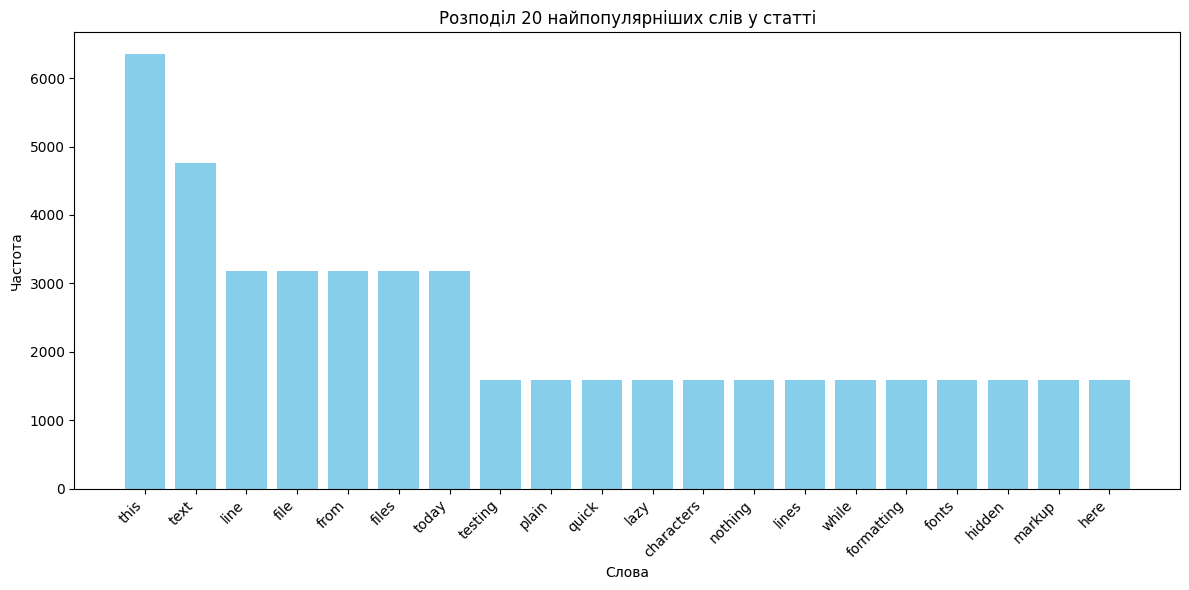

In [24]:
uploaded3 = files.upload()
file_name3 = list(uploaded3.keys())[0]

rdd_text = sc.textFile(file_name3)

# 1. Витягуємо слова, переводимо в нижній регістр, видаляємо пунктуацію
def clean_word(word):
    # Залишаємо тільки літери та цифри
    return re.sub(r'[^\w]', '', word).lower()

words_rdd = rdd_text.flatMap(lambda line: line.split()) \
                    .map(clean_word) \
                    .filter(lambda w: w != "")

# 2. Виключаємо слова, які містять цифри
no_digits_rdd = words_rdd.filter(lambda w: not any(char.isdigit() for char in w))

# 3. Вилучаємо короткі слова (до 3 символів включно)
long_words_rdd = no_digits_rdd.filter(lambda w: len(w) > 3)

# 4. Аналізуємо розподіл (рахуємо частоту)
word_counts = long_words_rdd.map(lambda w: (w, 1)) \
                            .reduceByKey(lambda a, b: a + b) \
                            .sortBy(lambda x: x[1], ascending=False)

# Беремо 20 найпопулярніших слів
top_20_words = word_counts.take(20)

print("Топ-20 найпопулярніших слів:")
for word, count in top_20_words:
    print(f"{word}: {count}")

# 5. Створення гістограми за допомогою matplotlib
words = [x[0] for x in top_20_words]
counts = [x[1] for x in top_20_words]

plt.figure(figsize=(12, 6))
plt.bar(words, counts, color='skyblue')
plt.title("Розподіл 20 найпопулярніших слів у статті")
plt.xlabel("Слова")
plt.ylabel("Частота")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [25]:
# Генерація списку транзакцій (не менше 100 записів)
transactions_list = [random.choice([101, 102, 103, 104]) for _ in range(150)]
rdd_transactions = sc.parallelize(transactions_list)

# Словник відповідності кодів товарів
products = {
    101: "Ноутбук",
    102: "Смартфон",
    103: "Планшет",
    104: "Монітор"
}

# Створення Broadcast-змінної
broadcast_products = sc.broadcast(products)

# Зіставлення кодів із назвами та підрахунок продажів
sales_counts = rdd_transactions.map(lambda code: (broadcast_products.value.get(code, "Невідомий товар"), 1)) \
                               .reduceByKey(lambda a, b: a + b)

print("Кількість продажів кожного товару:")
for product, count in sales_counts.collect():
    print(f"{product}: {count} шт.")

Кількість продажів кожного товару:
Монітор: 37 шт.
Планшет: 41 шт.
Смартфон: 33 шт.
Ноутбук: 39 шт.


In [26]:
# Генерація RDD із температурними вимірюваннями (100 записів від 15.0 до 40.0 градусів)
temperatures = [round(random.uniform(15.0, 40.0), 1) for _ in range(100)]
rdd_temps = sc.parallelize(temperatures)

# Створення акумуляторної змінної
high_temp_acc = sc.accumulator(0)

# Функція для перевірки аномальної температури
def check_anomaly(temp):
    global high_temp_acc
    if temp > 30.0:
        high_temp_acc.add(1)

# Використовуємо дію foreach для проходження по всьому RDD
rdd_temps.foreach(check_anomaly)

print(f"Загальна кількість вимірювань: {rdd_temps.count()}")
print(f"Кількість аномально високих температур (> 30°C): {high_temp_acc.value}")

Загальна кількість вимірювань: 100
Кількість аномально високих температур (> 30°C): 42


In [27]:
# Зупинка Spark контексту після завершення
sc.stop()